# Examen.ipynb — Підсумкова робота (pandas + статистика + PyTorch)

**Дані:** `exam.csv` (2 стовпчики: `alpha`, `beta`)

У цій роботі ми:
1. Формуємо `updated_df` (беремо записи, де `beta` кратне 16) і рахуємо кількість записів.
2. Знаходимо середнє арифметичне через `describe()`.
3. Рахуємо IQR та межі викидів (outliers) для `updated_df` (по `beta`).
4. Ділимо `alpha` на квартилі та знаходимо середнє `beta` у кожному квартилі.
5. Перевіряємо лінійний зв’язок (кореляція Пірсона + p-value).
6. Беремо останні 20–40 `alpha`, вибираємо двоцифрові, формуємо тензори і навчаємо невелику нейромережу для бінарної класифікації.


In [57]:
import pandas as pd
from scipy import stats

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

df = pd.read_csv('exam.csv')
df.head(10)


,alpha,beta
0,1,1255
1,1,444
2,1,2214
3,8,672
4,1,610
5,1,738
6,6,484
7,6,1020
8,1,1992
9,1,456


### Дослідження
- `pd.read_csv('exam.csv')` зчитує файл у датафрейм `df`.
- У нас є два стовпчики:
  - `alpha` — числова ознака,
  - `beta` — числова ознака.
- Далі ми формуємо **власну вибірку** `updated_df` за умовою (кратність 16 по `beta`) і працюємо вже з нею.


## 1) Сформуйте `updated_df` (beta кратне 16). Скільки записів у `updated_df`?
Робимо **булеву маску** в pandas.


In [58]:
# 1. Вибірка: залишаємо записи, де beta кратне 16
mask = (df['beta'] % 16 == 0)
updated_df = df[mask].copy()

print('Кількість записів у updated_df:', len(updated_df))
updated_df.head(10)


Кількість записів у updated_df: 3915


,alpha,beta
3,8,672
10,1,560
12,1,1984
28,1,800
33,1,1344
38,1,816
42,1,960
45,1,1008
49,1,1952
54,4,1344


### Дослідження
- Вираз `df['beta'] % 16 == 0` повертає `True/False` для кожного рядка.
- Якщо `True` → `beta` ділиться на 16 без остачі.
- `df[mask]` залишає тільки ті рядки, що підходять під умову.


### Висновок
Ми отримали `updated_df` — це підвибірка, яка відповідає нашій умові варіанту (кратність 16 по стовпчику `beta`).


## 2) Середнє арифметичне значення у вибірці:
Знайдемо середнє для `alpha` і для `beta` у `updated_df`.


In [59]:
desc = updated_df.describe()
desc


,alpha,beta
count,3915.000000,3915.000000
mean,51.491188,903.335888
std,41.488954,388.736249
min,1.000000,272.000000
25%,20.000000,608.000000
50%,42.000000,832.000000
75%,72.000000,1152.000000
max,234.000000,2160.000000


In [60]:
# 2. Середні значення (mean) через describe()
mean_alpha = desc.loc['mean', 'alpha']
mean_beta = desc.loc['mean', 'beta']

print(f"Середнє alpha = {mean_alpha:.3f}")
print(f"Середнє beta  = {mean_beta:.3f}")


Середнє alpha = 51.491
Середнє beta  = 903.336


### Дослідження
- `describe()` дає описову статистику по числових стовпчиках.
- Середнє значення — це рядок `mean`.
- Ми не рахуємо вручну, а **витягуємо** його з `describe()`:
  - `desc.loc['mean','alpha']`
  - `desc.loc['mean','beta']`


### Висновок
Середнє арифметичне для `alpha` та `beta` у вибірці `updated_df` знайдено через `describe()`.


## 3) IQR та межі викидів для `updated_df` (по `beta`)
Квартилі беремо теж через `describe()`.


In [61]:
# 3. IQR та межі викидів (outliers) для beta
beta_desc = updated_df['beta'].describe()

q1 = beta_desc['25%']
q3 = beta_desc['75%']
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Q1 = {q1:.3f}")
print(f"Q3 = {q3:.3f}")
print(f"IQR = {iqr:.3f}")
print(f"Нижня межа (lower_bound) = {lower_bound:.3f}")
print(f"Верхня межа (upper_bound) = {upper_bound:.3f}")

outliers = updated_df[(updated_df['beta'] < lower_bound) | (updated_df['beta'] > upper_bound)]
print("Кількість викидів:", len(outliers))

outliers.head(10)


Q1 = 608.000
Q3 = 1152.000
IQR = 544.000
Нижня межа (lower_bound) = -208.000
Верхня межа (upper_bound) = 1968.000
Кількість викидів: 23


,alpha,beta
12,1,1984
93,1,2032
204,1,2032
429,1,2016
438,1,2032
459,1,2000
485,1,2016
692,1,2032
811,1,1984
951,1,2016


### Дослідження
- **IQR (міжквартильний розмах)**: `IQR = Q3 - Q1`, де `Q1` — 25%, `Q3` — 75%.
- Межі викидів (правило 1.5*IQR):
  - `lower_bound = Q1 - 1.5 * IQR`
  - `upper_bound = Q3 + 1.5 * IQR`
- Викиди — це значення, які виходять за ці межі.


### Висновок
Межі викидів для `beta` обчислені через IQR. Датафрейм `outliers` показує записи, які потенційно є викидами.


## 4) Квартилі для `alpha` + середнє `beta` в кожному квартилі
Використовуємо `pd.qcut` (q=4) і `groupby`.


In [62]:
# 4. Квартилі alpha (qcut) + середнє beta у кожному квартилі
updated_df['alpha_q'] = pd.qcut(
  updated_df['alpha'],
  q=4,
  labels=['Q1', 'Q2', 'Q3', 'Q4']
)

beta_mean = updated_df.groupby('alpha_q')['beta'].mean()
beta_count = updated_df.groupby('alpha_q')['beta'].count()

result = pd.DataFrame({'count': beta_count, 'beta_mean': beta_mean})
result


C:\Users\User\AppData\Local\Temp\ipykernel_4888\2352377442.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  beta_mean = updated_df.groupby('alpha_q')['beta'].mean()
C:\Users\User\AppData\Local\Temp\ipykernel_4888\2352377442.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  beta_count = updated_df.groupby('alpha_q')['beta'].count()


,count,beta_mean
alpha_q,,
Q1,1034,1017.237911
Q2,955,937.365445
Q3,1013,853.923001
Q4,913,793.568456


### Дослідження
- `pd.qcut(..., q=4)` ділить значення `alpha` на **4 рівні групи** (квартилі) за кількістю елементів.
- Ми підписуємо квартилі як `Q1, Q2, Q3, Q4`.
- Далі `groupby('alpha_q')['beta'].mean()` рахує **середнє значення beta** всередині кожного квартилю `alpha`.
- Додатково ми вивели `count`, щоб бачити скільки записів у кожній групі.

Інтерпретація проста: 
- Якщо `beta_mean` росте від Q1 до Q4 — значить з ростом `alpha` середній `beta` теж підтягується (і навпаки).
- Це допомагає зрозуміти, як змінюється `beta`, якщо `alpha` переходить у “вищі” квартилі.


### Висновок
Ми отримали таблицю: скільки записів у квартилі та яке середнє значення `beta` для кожного квартилю `alpha`. Це зручно для порівняння груп.


## 5) Кореляція Пірсона + p-value
Перевіряємо, чи є лінійний зв’язок між `alpha` та `beta` у `updated_df`.


In [63]:
# 5. Кореляція Пірсона + p-value
corr, p_value = stats.pearsonr(updated_df['alpha'], updated_df['beta'])

print(f"Pearson r = {corr:.6f}")
print(f"p-value   = {p_value:.3e}")

if p_value < 0.05:
  print("Висновок: зв’язок статистично значущий (p < 0.05).")
else:
  print("Висновок: статистично значущого зв’язку не виявлено (p >= 0.05).")


Pearson r = -0.215923
p-value   = 1.587e-42
Висновок: зв’язок статистично значущий (p < 0.05).


### Дослідження
- Кореляція Пірсона показує **лінійний зв’язок** між двома змінними:
  - `r` близько до `1` → сильний прямий зв’язок;
  - `r` близько до `-1` → сильний зворотній зв’язок;
  - `r` близько до `0` → лінійного зв’язку майже немає.
- `p-value` відповідає за статистичну значущість:
  - якщо `p < 0.05`, то зв’язок вважається значущим (малоймовірно, що це випадковість).
- Навіть якщо `p` дуже мале, `r` може бути невеликим — тоді зв’язок є, але він **слабкий**.


### Висновок
За значенням `r` ми бачимо напрямок і силу лінійного зв’язку, а за `p-value` — чи цей зв’язок статистично значущий.


## 6) Нейромережа (PyTorch): двоцифрові `alpha` з останніх 20–40 записів
Правило для класів:
- **клас 1** — якщо сума цифр числа **менша 10**,
- **клас 0** — якщо сума цифр **10 або більше**.

Ознаки формуємо як: `[десятки, одиниці]`.


In [64]:
# 6.1 Беремо останні 40 значень alpha та відбираємо двоцифрові
tail_alpha = updated_df['alpha'].tail(40)
two_digit_alpha = tail_alpha[(tail_alpha >= 10) & (tail_alpha <= 99)].astype(int)

print('Останні 40 alpha:')
print(tail_alpha.tolist())

print('\nДвоцифрові alpha (10..99):')
print(two_digit_alpha.tolist())
print('\nКількість двоцифрових:', len(two_digit_alpha))


Останні 40 alpha:
[88, 153, 50, 72, 92, 64, 60, 56, 84, 90, 50, 115, 66, 110, 90, 45, 126, 105, 176, 176, 40, 120, 126, 99, 102, 80, 162, 207, 60, 40, 88, 72, 90, 72, 152, 84, 171, 70, 55, 102]

Двоцифрові alpha (10..99):
[88, 50, 72, 92, 64, 60, 56, 84, 90, 50, 66, 90, 45, 40, 99, 80, 60, 40, 88, 72, 90, 72, 84, 70, 55]

Кількість двоцифрових: 25


### Дослідження
- Ми беремо `.tail(40)` — це останні 40 записів по `alpha` у `updated_df`.
- Далі фільтруємо лише двоцифрові значення: від 10 до 99.
- Саме з них будемо будувати навчальні приклади для нейромережі.


In [65]:
# 6.2 Формуємо X - (десятки, одиниці) та y - (сума цифр < 10)
nums = two_digit_alpha.tolist()

X_list = []
y_list = []

for n in nums:
  tens = n // 10
  ones = n % 10

  X_list.append([float(tens), float(ones)])

  if (tens + ones) < 10:
    y_list.append([1.0])
  else:
    y_list.append([0.0])

X = torch.tensor(X_list, dtype=torch.float32)
y = torch.tensor(y_list, dtype=torch.float32)

print("X shape:", X.shape)
print("y shape:", y.shape)

# Подивимось перші 5 прикладів
for i in range(min(5, len(nums))):
  print(f"Число {float(nums[i]):4.1f} -> X = {X_list[i]}, y = {int(y_list[i][0])}")


X shape: torch.Size([25, 2])
y shape: torch.Size([25, 1])
Число 88.0 -> X = [8.0, 8.0], y = 0
Число 50.0 -> X = [5.0, 0.0], y = 1
Число 72.0 -> X = [7.0, 2.0], y = 1
Число 92.0 -> X = [9.0, 2.0], y = 0
Число 64.0 -> X = [6.0, 4.0], y = 0


### Дослідження
- Наприклад, число **21** перетворюємо у вектор ознак **[2.0, 1.0]**.
- Це зручно, бо нейромережа навчається не на самому числі, а на його “складових”.
- Ціль (клас) задаємо правилом:
  - якщо сума цифр < 10 → клас 1,
  - якщо сума цифр ≥ 10 → клас 0.
- Це і є наша логіка для бінарної класифікації.


In [66]:
# 6.3 Розбиваємо на train (80%) та test (20%)
torch.manual_seed(42)

n = len(X)
idx = torch.randperm(n)

split = int(n * 0.8) # індекс розбиття '0.8' від загальної кількості 'n', тобто '80%' для тренування та '20%' для тесту
train_idx = idx[:split] # індекси для тренувального набору
test_idx = idx[split:] # індекси для тестового набору

X_train = X[train_idx]
y_train = y[train_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print("Train size:", len(X_train))
print("Test size :", len(X_test))


Train size: 20
Test size : 5


### Дослідження
- Ми перемішуємо індекси через `torch.randperm(n)`.
- 80% беремо на навчання, 20% — на тест.
- Так ми перевіряємо, чи модель вміє узагальнювати, а не просто запам’ятала приклади.


In [67]:
# 6.4 Створюємо модель нейромережі
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

class DigitsNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1 = nn.Linear(2, 8)
    self.tanh = nn.Tanh()
    self.layer2 = nn.Linear(8, 4)
    self.relu = nn.ReLU()
    self.layer3 = nn.Linear(4, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, obj):
    obj = self.layer1(obj)
    obj = self.tanh(obj)
    obj = self.layer2(obj)
    obj = self.relu(obj)
    obj = self.layer3(obj)
    return self.sigmoid(obj)

model = DigitsNet().to(device)
model


DigitsNet(
  (layer1): Linear(in_features=2, out_features=8, bias=True)
  (tanh): Tanh()
  (layer2): Linear(in_features=8, out_features=4, bias=True)
  (relu): ReLU()
  (layer3): Linear(in_features=4, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

### Дослідження
- Ми робимо невелику модель:
  - створюємо шари в `__init__`,
  - у `forward()` послідовно пропускаємо дані через шари.
- `Sigmoid()` на виході дає ймовірність класу 1 (від 0 до 1).


epoch: 0, loss: 0.70950
epoch: 100, loss: 0.30743
epoch: 200, loss: 0.15516
epoch: 300, loss: 0.06228
epoch: 400, loss: 0.03594
epoch: 500, loss: 0.02357
epoch: 600, loss: 0.01656
epoch: 700, loss: 0.01229
epoch: 800, loss: 0.00956
epoch: 900, loss: 0.00773


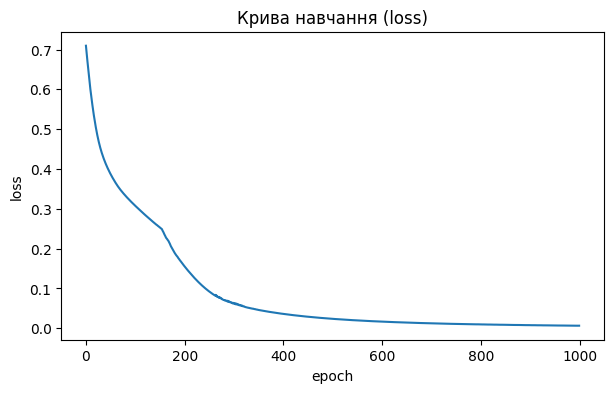

In [68]:
# 6.5 Навчаємо модель
loss_fn = nn.BCELoss()
opt = optim.Adam(model.parameters(), lr=0.01)

epochs = 1000
losses = []

for epoch in range(epochs):
  model.train()
  opt.zero_grad()

  pred = model(X_train)
  loss = loss_fn(pred, y_train)

  loss.backward()
  opt.step()

  losses.append(loss.item())

  if epoch % 100 == 0:
    print(f"epoch: {epoch}, loss: {loss.item():.5f}")

# Візуалізуємо графік кривої навчання:
plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Крива навчання (loss)')
plt.show()


### Дослідження
- `BCELoss()` підходить, бо ми робимо **бінарну класифікацію** (0 або 1).
- На кожній епосі:
  - рахуємо прогноз `pred`,
  - рахуємо `loss`,
  - робимо `loss.backward()` і `opt.step()`.
- Якщо `loss` падає — модель навчається.


In [69]:
# 6.6 Оцінюємо модель на тесті
model.eval()

with torch.no_grad():
  pred_test = model(X_test)
  y_pred = (pred_test >= 0.5).float()

correct = (y_pred == y_test).sum().item()
total = len(y_test)

accuracy = correct / total if total > 0 else 0
print(f"Accuracy на тесті: {accuracy:.3f} ({int(correct)}/{int(total)})")


Accuracy на тесті: 1.000 (5/5)


### Дослідження
- Ми отримуємо ймовірності (бо є sigmoid).
- Далі переводимо у клас:
  - якщо `p >= 0.5` → клас 1,
  - інакше → клас 0.
- `accuracy` рахуємо вручну, частку правильних відповідей.


In [70]:
# 6.7 Прогнози на нових даних
test_numbers = [10, 12, 15, 18, 21, 25, 39, 48, 57, 66, 72, 88, 90, 99]

X_new = []
for n in test_numbers:
  X_new.append([float(n // 10), float(n % 10)])

X_new = torch.tensor(X_new, dtype=torch.float32).to(device)

with torch.no_grad():
  proba_new = model(X_new).squeeze().cpu().tolist()

for i, n in enumerate(test_numbers):
  p = float(proba_new[i])
  cls = 1 if p >= 0.5 else 0
  print(f"Число {float(n):4.1f} -> ймовірність класу 1 = {p:.3f}, прогнозований клас = {cls}")


Число 10.0 -> ймовірність класу 1 = 1.000, прогнозований клас = 1
Число 12.0 -> ймовірність класу 1 = 1.000, прогнозований клас = 1
Число 15.0 -> ймовірність класу 1 = 1.000, прогнозований клас = 1
Число 18.0 -> ймовірність класу 1 = 0.777, прогнозований клас = 1
Число 21.0 -> ймовірність класу 1 = 1.000, прогнозований клас = 1
Число 25.0 -> ймовірність класу 1 = 1.000, прогнозований клас = 1
Число 39.0 -> ймовірність класу 1 = 0.016, прогнозований клас = 0
Число 48.0 -> ймовірність класу 1 = 0.016, прогнозований клас = 0
Число 57.0 -> ймовірність класу 1 = 0.016, прогнозований клас = 0
Число 66.0 -> ймовірність класу 1 = 0.016, прогнозований клас = 0
Число 72.0 -> ймовірність класу 1 = 0.999, прогнозований клас = 1
Число 88.0 -> ймовірність класу 1 = 0.016, прогнозований клас = 0
Число 90.0 -> ймовірність класу 1 = 1.000, прогнозований клас = 1
Число 99.0 -> ймовірність класу 1 = 0.016, прогнозований клас = 0


### Висновок
- Модель навчилися визначати клас для двоцифрових чисел за правилом “сума цифр < 10”.  
- Вивід показує ймовірність класу 1 і кінцевий прогнозований клас для кожного тестового числа.
## Загальний підсумок
- Ми сформували `updated_df` за умовою (beta кратне 16) і порахували кількість записів.
- Через `describe()` дістали середні значення для `alpha` і `beta`.
- Через IQR визначили межі викидів для `beta` і знайшли потенційні outliers.
- За допомогою `qcut` порівняли середній `beta` у квартилях `alpha`.
- Перевірили лінійний зв’язок через кореляцію Пірсона та p-value.
- Побудували навчальний набір з двоцифрових `alpha` і навчили невелику нейромережу на PyTorch.
